# LeetCode #560: Subarray Sum Equals K

https://leetcode.com/problems/subarray-sum-equals-k/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force (All Subarrays)** | $O(n^2)$ | $O(1)$ |
| **Optimal: Prefix Sum + HashMap ★** | $O(n)$ | $O(n)$ |

---

## Understanding the Methods

### Brute Force (All Subarrays)
For each starting index, compute the running sum and check if it equals k. Count all valid subarrays.

### Optimal: Prefix Sum + HashMap ★
Maintain a running prefix sum and a hash map counting how many times each prefix sum has occurred. For the current prefix sum `S`, the number of subarrays ending here with sum k equals the count of prefix sums equal to `S - k` seen so far.

**Why this is better than Brute Force:** Each element is processed once, and the hash map lookup is O(1), giving O(n) total time.

**Constraints:**
* 1 <= nums.length <= 2 * 10^4
* -1000 <= nums[i] <= 1000
* -10^7 <= k <= 10^7

## Solutions

### C#

In [ ]:
public class Solution {
    public int SubarraySum(int[] nums, int k) {
        var map = new Dictionary<int, int> { { 0, 1 } };
        int prefix = 0, count = 0;
        foreach (int n in nums) {
            prefix += n;
            if (map.ContainsKey(prefix - k))
                count += map[prefix - k];
            map[prefix] = map.GetValueOrDefault(prefix, 0) + 1;
        }
        return count;
    }
}

### Python

In [ ]:
from collections import defaultdict

class Solution:
    def subarraySum(self, nums: list[int], k: int) -> int:
        prefix_count = defaultdict(int)
        prefix_count[0] = 1
        prefix = 0
        count = 0
        for n in nums:
            prefix += n
            count += prefix_count[prefix - k]
            prefix_count[prefix] += 1
        return count

### Go

In [ ]:
func subarraySum(nums []int, k int) int {
    prefixCount := map[int]int{0: 1}
    prefix, count := 0, 0
    for _, n := range nums {
        prefix += n
        count += prefixCount[prefix-k]
        prefixCount[prefix]++
    }
    return count
}

### Rust

In [ ]:
use std::collections::HashMap;

impl Solution {
    pub fn subarray_sum(nums: Vec<i32>, k: i32) -> i32 {
        let mut prefix_count = HashMap::new();
        prefix_count.insert(0, 1);
        let mut prefix = 0;
        let mut count = 0;
        for &n in &nums {
            prefix += n;
            count += prefix_count.get(&(prefix - k)).unwrap_or(&0);
            *prefix_count.entry(prefix).or_insert(0) += 1;
        }
        count
    }
}

## Example Scenarios

### 1. Common Case — Repeated Prefix Sums
**Input:** `nums = [1,1,1], k = 2`

Prefix sums run 1, 2, 3. The map starts seeded with `{0: 1}` so that a prefix equal to $k$ itself counts. At `i=1` the prefix is 2 and $P - k = 0$ is in the map (count 1) → +1. At `i=2` the prefix is 3 and $P - k = 1$ is in the map (count 1) → +1.

**Output: 2** — the subarrays `[0..1]` and `[1..2]`, which overlap.

### 2. Slightly Complex — Negatives Break the Sliding Window
**Input:** `nums = [1,2,3,-3,1,1,1], k = 3`

Prefix sums run 1, 3, 6, 3, 4, 5, 6. Because of the `-3` the prefix sequence is **not** monotonic, so a two-pointer sliding window (which relies on the sum growing as the window widens) is invalid here — the hash map is not an optimization, it is the only correct linear method. Prefix 3 appears at both `i=1` and `i=3`, so when the final step (`i=6`, $P = 6$) looks up $P - k = 3$ the count is already 2 and that one step adds two subarrays.

**Output: 6** — `[0..1]`, `[2..2]`, `[0..3]`, `[1..4]`, `[2..6]`, `[4..6]`.

### 3. Edge Case: Time Factor — All Zeros, k = 0
**Input:** `nums = [0,0,0,0,0,0], k = 0`

Every prefix is 0 and $P - k = 0$ every time, so the hits are 1, 2, 3, 4, 5, 6 and the running answer is 1, 3, 6, 10, 15, 21.

**Output: 21** $= \frac{6 \cdot 7}{2}$ — literally every subarray qualifies. The loop still runs $n$ times, so time stays $O(n)$ even though the *answer* is $\Theta(n^2)$. At the constraint limit $n = 2 \times 10^4$ the answer is $\approx 2 \times 10^8$, which fits in a 32-bit int but is close enough that the accumulator should be `long`/`i64` in C#, Go and Rust.

### 4. Edge Case: Space Factor — All Prefix Sums Distinct
**Input:** `nums = [1,2,4,8,16], k = 7`

Prefix sums 1, 3, 7, 15, 31 are all distinct, so the map ends as `{0:1, 1:1, 3:1, 7:1, 15:1, 31:1}` — $n + 1$ entries, the worst case that makes the space bound $O(n)$. Only `i=2` scores: $P = 7$, $P - k = 0$, which is the seed.

**Output: 1** — only `[0..2]` = 1+2+4 = 7. (The brute-force $O(n^2)$ scan would use $O(1)$ space here; this is the trade the hash map makes.)

### 5. Almost-Impossible but Plausible — Extreme Values Cancelling
**Input:** `nums = [1000,1000,-1000,-1000,1000], k = 0`

Values sit at the $\pm 1000$ constraint limit and cancel exactly, so the prefix 1000 recurs: prefixes are 1000, 2000, 1000, 0, 1000. At `i=4`, `count[1000]` is already 2, so that single step contributes 2 subarrays.

**Output: 4** — `[1..2]`, `[0..3]`, `[3..4]`, `[1..4]`. Note `k = 0` is legal and is *not* a signal to stop: the seeded `{0: 1}` entry is what lets a whole-prefix-zero subarray such as `[0..3]` be counted. Prefix sums here stay within $\pm 2000$; at the constraint limit they reach $2 \times 10^7$, still inside `int32`, and $k$ itself spans $\pm 10^7$.

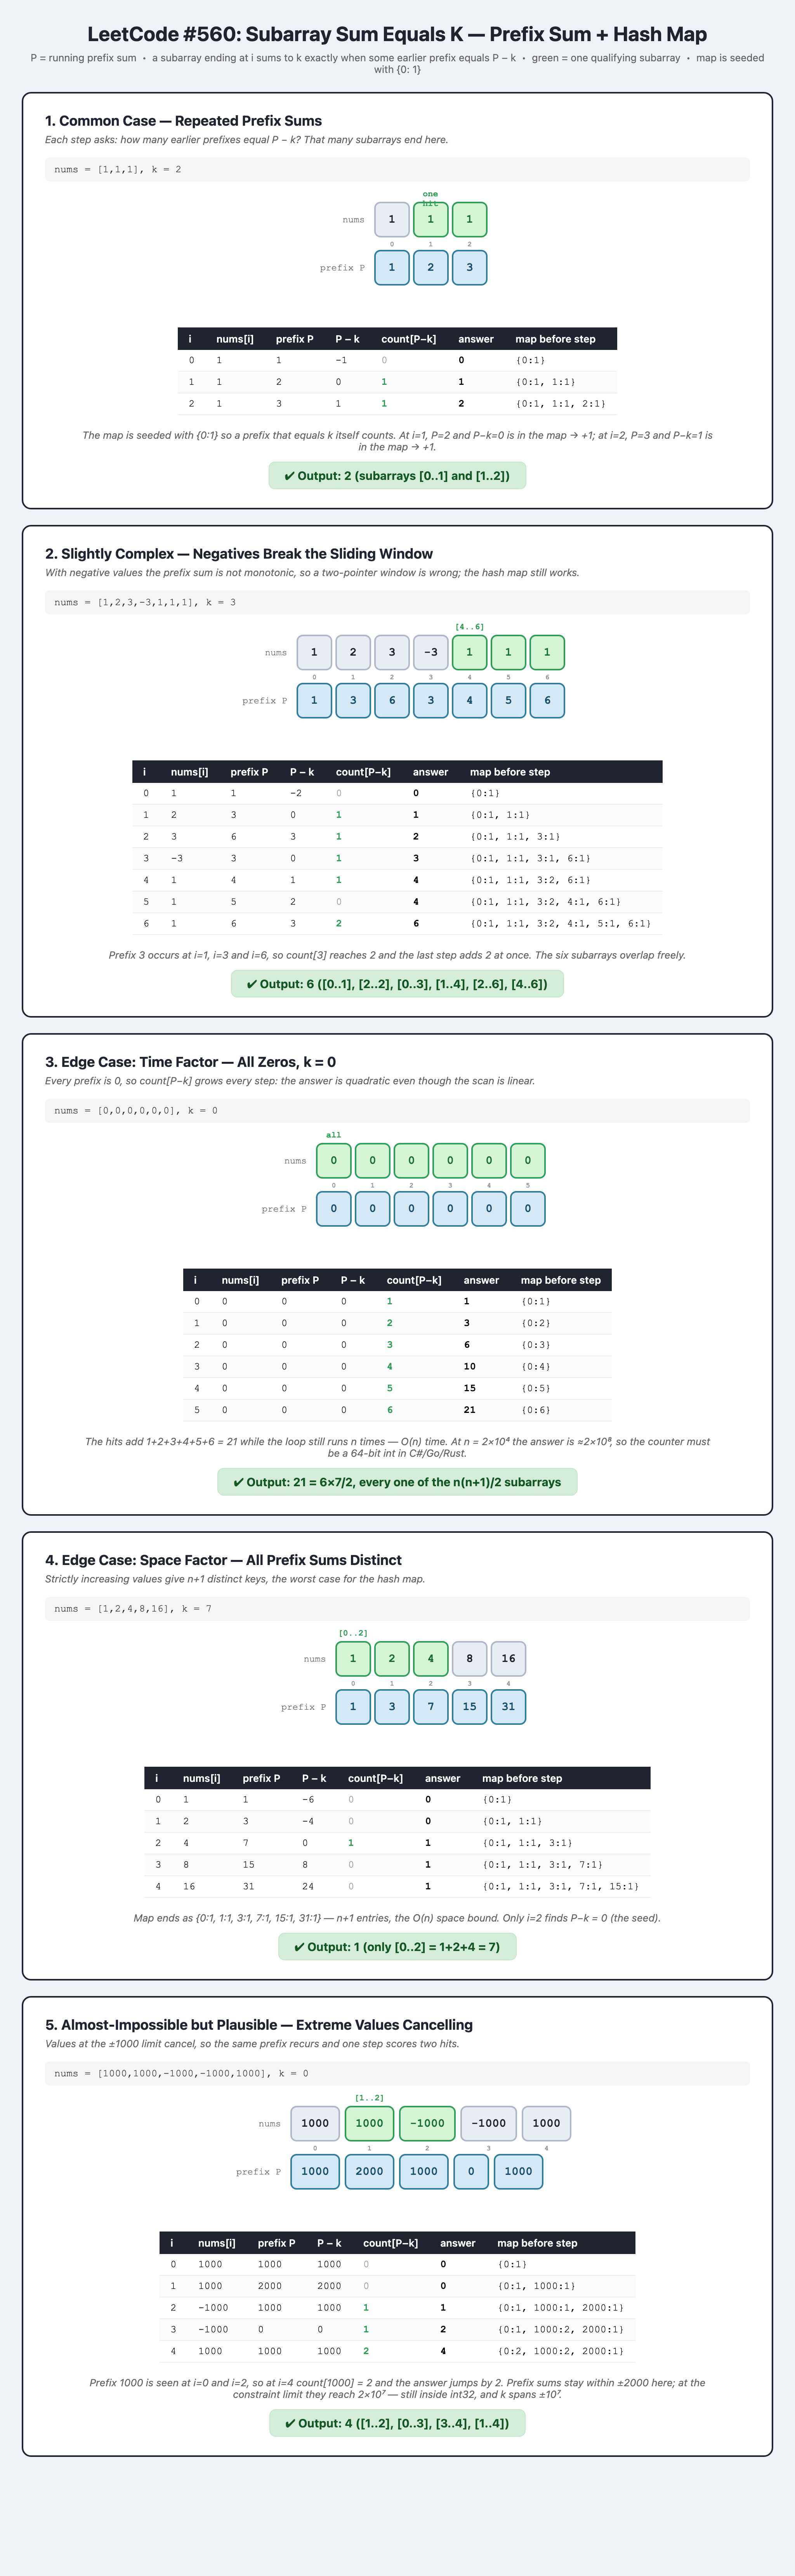